# v11 D (GPU 1): learning a NEW language (Indonesian) after a count-matched lesion / under silencing, 5 seeds
- Starts: distant phase 20 and related phase 16 (both before any breakdown) + a fresh untrained model as the baseline.
- Training: 1,500 steps on English -> Indonesian, learning rate 1e-4. Score: chrF on 200 FLORES sentences (step 0 and end).
- Conditions: untouched · self@1.0 vs task@1.0 · self@0.5 vs task@0.5 vs look-alike@0.5, for **lesion** and for **silence**. Seed 0 of everything first.
Results: `analysis/v11/train_indonesian/` · progress: `tail -f logs/v11_D_indonesian.log`

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "1"; LOG = "v11_D_indonesian"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
FILES, HF_REPO = [], None
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)
if not FILES:
    print("could not list the HF repo: only checkpoints already on this machine will be used")

def have(run, ph):
    return bool(glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"))

def get(run, phases):
    """download what is missing; returns the phases that are on this machine afterwards"""
    ok = []
    for ph in phases:
        if not have(run, ph):
            name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
            if name:
                try:
                    hf_hub_download(HF_REPO, name[0], local_dir="runs")
                except Exception as e:
                    print("download failed:", run, ph, type(e).__name__, e)
        if have(run, ph):
            ok.append(ph)
        else:
            print("not available (not here, not on HF):", run, ph)
    return ok

def run(langset, *cmd):
    """one call of core_v11.py; output shown here AND appended to logs/<LOG>.log (watch with: tail -f logs/<LOG>.log)"""
    env = {**os.environ, "CML_LANGSET": langset}; os.makedirs("logs", exist_ok=True)
    p = subprocess.Popen([sys.executable, "-u", "core_v11.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    with open(f"logs/{LOG}.log", "a") as log:
        for line in p.stdout:
            print(line, end=""); log.write(line); log.flush()
    p.wait(); print("exit code", p.returncode)

def summary(part, out=None):
    cmd = [sys.executable, "core_v11.py", "--summarize", "--part", part] + (["--out", out] if out else [])
    r = subprocess.run(cmd, capture_output=True, text=True); print(r.stdout[-12000:]); print(r.stderr[-3000:])

DIST, HIN, MIX, REL = "v4b_continual_s0", "v4b_only_hi_s0", "v6b_mixed_s0", "v8_indic_continual_s0"

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


In [2]:
r = subprocess.run([sys.executable, "-u", "prep_newtasks.py"], capture_output=True, text=True); print(r.stdout[-3000:]); print(r.stderr[-3000:])
print("Indonesian data there:", all(os.path.exists(f"data/newtask/indonesian/{s}.jsonl") for s in ["train", "val", "test"]))

indonesian  example: '"We now have 4-month-old mice that are non-diabetic that used to be di' -> '“Saat ini ada mencit umur 4 bulan nondia'
sentiment   example: "it 's a charming and often affecting journey ." -> 'positive'
topic       example: 'At wireless show, services take center stage Games, graphic ring tones' -> 'science'
addition    example: '1 + 5' -> '6'

/venv/main/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(

Indonesian data there: True


In [3]:
STARTS = [("distant", "distant", DIST, 20), ("indic", "related", REL, 16)]
COMMON = ["--part", "train", "--task", "indonesian", "--lr", "1e-4", "--steps", "1500"]
for seeds in ["0", "1,2,3,4"]:
    for langset, fam, r, ph in STARTS:
        if get(r, [ph]):
            for mode in ["lesion", "silence"]:
                run(langset, *COMMON, "--mode", mode, "--family", fam, "--model", f"{fam}{ph}={r}:{ph}", "--seeds", seeds)
    run("distant", *COMMON, "--family", "fresh", "--model", "fresh", "--seeds", seeds)
    summary("train", "train_indonesian")

p020_zh.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

start model: distant20 = v4b_continual_s0 phase 20 (last trained on zh) | languages hi, zh, ar


  enc0: working 2560, self 1201, task 1359 -> count-matched n_max 1201
  enc1: working 2560, self 1116, task 1444 -> count-matched n_max 1116
  enc2: working 2560, self 1151, task 1409 -> count-matched n_max 1151
  enc3: working 2560, self 1464, task 1096 -> count-matched n_max 1096
  dec0: working 2560, self 1410, task 1150 -> count-matched n_max 1150
  dec1: working 2560, self 1033, task 1527 -> count-matched n_max 1033
  dec2: working 2560, self 1044, task 1516 -> count-matched n_max 1044
  dec3: working 2560, self 1409, task 1151 -> count-matched n_max 1151
  self found in 6s


runs to do in this call: 6 (mode lesion; conditions ['none', 'self@1.0', 'task@1.0', 'self@0.5', 'task@0.5', 'look@0.5']; seeds [0]; finished runs are skipped)


  distant20 | indonesian | none    | none      | seed 0 | 0 neurons | loss 10.669 -> 1.211 | chrF 5.2 -> 48.7 | 104s | left in this call: 5 runs, about 9 min


  distant20 | indonesian | lesion  | self@1.0  | seed 0 | 8942 neurons | loss 10.754 -> 1.270 | chrF 3.3 -> 46.8 | 103s | left in this call: 4 runs, about 7 min


... (144 outputs left out)

  fresh | indonesian | none    | none      | seed 3 | 0 neurons | loss 10.500 -> 1.811 | chrF 2.0 -> 21.7 | 102s | left in this call: 1 runs, about 2 min


  fresh | indonesian | none    | none      | seed 4 | 0 neurons | loss 10.383 -> 1.814 | chrF 0.9 -> 24.0 | 102s | left in this call: 0 runs, about 0 min
done


exit code 0


=== train (train_indonesian): held-out loss on the trained language MINUS the untouched model's, same start and seed ===
average over starts and seeds; step 0 = right after the intervention, before any training
step                          0       100     300     1500
family  mode    dose group                                
distant lesion  0.5  look   0.0873 -0.0209 -0.0061  0.0112
                     self   0.0931  0.0355  0.0359  0.0210
                     task  -0.2008 -0.0206 -0.0093  0.0091
                1.0  self   0.2077  0.1696  0.1076  0.0533
                     task   0.6265 -0.0266 -0.0021  0.0278
        silence 0.5  look   0.0792  0.0323  0.0427  0.0232
                     self   0.0519  0.1084  0.0833  0.0329
                     task  -0.1727  0.0358  0.0390  0.0228
                1.0  self   0.0620  0.2806  0.2152  0.0843
                     task   0.5855  0.1103  0.0974  0.0563
related lesion  0.5  look  -0.3157 -0.0517 -0.0068  0.0066
                     s

=== train (train_indonesian): held-out loss on the trained language MINUS the untouched model's, same start and seed ===
average over starts and seeds; step 0 = right after the intervention, before any training
step                          0       100     300     1500
family  mode    dose group                                
distant lesion  0.5  look   0.0873 -0.0209 -0.0061  0.0112
                     self   0.0931  0.0355  0.0359  0.0210
                     task  -0.2008 -0.0206 -0.0093  0.0091
                1.0  self   0.2077  0.1696  0.1076  0.0533
                     task   0.6265 -0.0266 -0.0021  0.0278
        silence 0.5  look   0.0792  0.0323  0.0427  0.0232
                     self   0.0519  0.1084  0.0833  0.0329
                     task  -0.1727  0.0358  0.0390  0.0228
                1.0  self   0.0620  0.2806  0.2152  0.0843
                     task   0.5855  0.1103  0.0974  0.0563
related lesion  0.5  look  -0.3157 -0.0517 -0.0068  0.0066
                     s

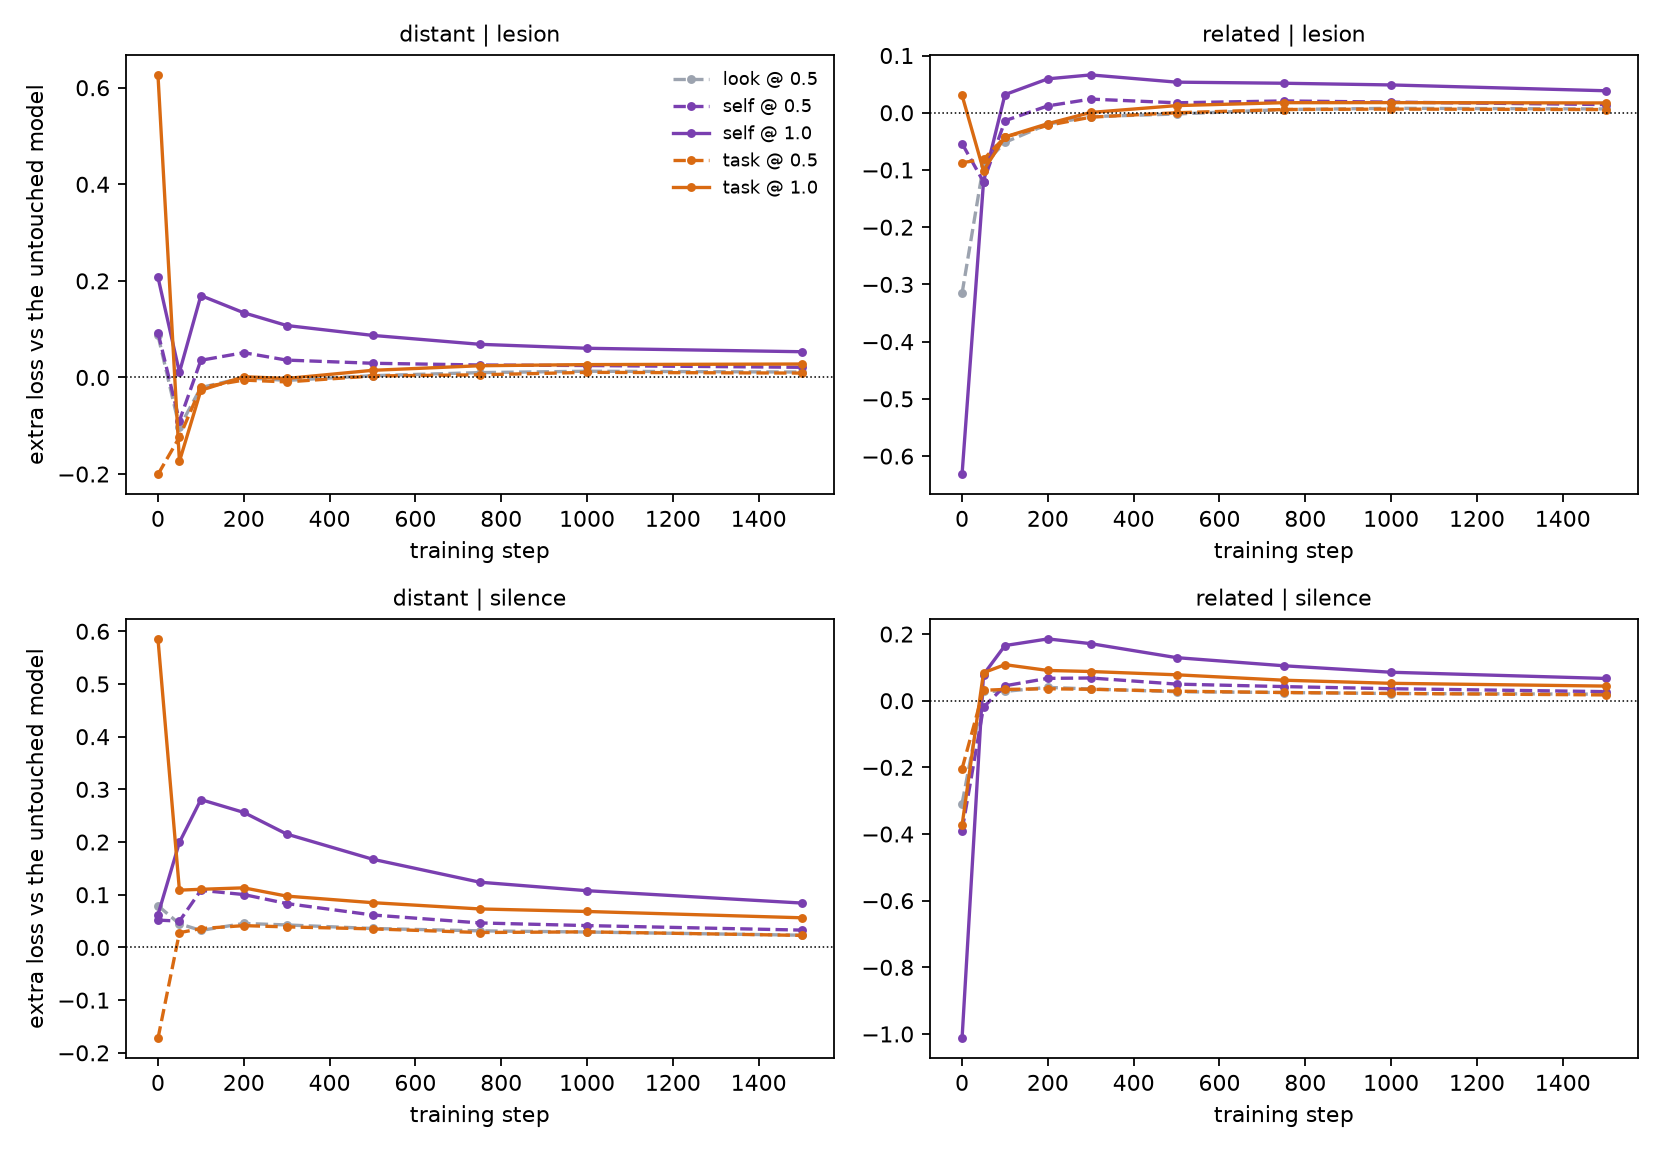

In [4]:
summary("train", "train_indonesian")
if os.path.exists("analysis/v11/train_indonesian/curves.png"): display(Image("analysis/v11/train_indonesian/curves.png"))